# Module 2 · Markov chains: learn transitions, predict several days ahead
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **Does knowing today's bike-rental state improve tomorrow's prediction, and how does that information change over a week or a month?**

Guided work: about 40–50 minutes. Exercises: about 25–35 minutes. This completes the two-week Concept Lab 1 with Module 1; it is not a new project. The probability and matrix ideas below are self-contained.

By the end, you should be able to define useful states, estimate a transition matrix without future information, compute and simulate multistep probabilities, and compare chronological forecasts against simple baselines.

[Course home](../index.html) · [Interactive lesson](../modules/module02.html) · [Project guide](../project-guide.html) · [Data provenance](../data/PROVENANCE.md)

Use **Restart Kernel and Run All**. Run from the course root or `notebooks/`. This notebook uses the bundled observed CSV and the existing course dependencies; no account, download, API key, or Python web server is required. Keep exercise answers in your own copy.

## 1. A useful state is a modeling choice
Let $X_t$ denote **completed bike rentals on calendar day** $t$. With the scenario threshold $c=4000$ rentals/day, define

$$Y_t=1\{X_t>c\},\qquad \mathcal S=\{0,1\}.$$

State $0$ means at most 4,000 completed rentals; state $1$ means more than 4,000. A day with exactly 4,000 is in state $0$. Time advances in one-day steps. The data give one observed path of these states, not independent observed years.

The threshold is a reporting assumption, not measured fleet capacity. Completed rentals do not measure unique bikes, unmet requests, or latent demand. Thresholding discards information: 4,001 and 6,000 rentals have the same state. Even if a detailed count process were Markov, this grouped binary process need not be Markov.

**Predict before running:** Will a high-rental day be followed by another high-rental day more often than a low-rental day? Could shared season or weather create that pattern without a causal effect of today's rentals?

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 6231
plt.rcParams.update({"figure.figsize": (10, 3.5), "font.size": 11})

### Audit the same observed data and preserve chronology
The bundled file contains 365 observed daily records from UCI Bike Sharing (Fanaee-T, 2013; [DOI 10.24432/C5W894](https://doi.org/10.24432/C5W894)), licensed **CC BY 4.0**, covering Capital Bikeshare in Washington, D.C. The provenance file records attribution, units, transformations, and hashes.

We retain the Module 1 split: January–August for fitting and September–December for later evaluation. The later period was already inspected in Module 1, so it is now a **development holdout**, not pristine final validation. A final project claim after model selection needs a fresh evaluation period, or a prespecified rolling evaluation design on observations not already used for model development.

In [2]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/bike_daily_2011.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
csv_path = ROOT / "data/bike_daily_2011.csv"
source = json.loads((ROOT / "data/source_metadata.json").read_text())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(csv_path, parse_dates=["dteday"])
assert bike["dteday"].tolist() == pd.date_range("2011-01-01", "2011-12-31").tolist()
assert bike["cnt"].notna().all() and bike["cnt"].ge(0).all()
assert np.equal(bike["cnt"], np.floor(bike["cnt"])).all()
assert bike["workingday"].isin([0, 1]).all()
assert (bike["mnth"] == bike["dteday"].dt.month).all()

In [3]:
THRESHOLD, SPLIT_DATE = 4000, pd.Timestamp("2011-09-01")
bike["y"] = (bike["cnt"] > THRESHOLD).astype(int)
train = bike.loc[bike["dteday"] < SPLIT_DATE].copy()
test = bike.loc[bike["dteday"] >= SPLIT_DATE].copy()
y_train, y_all = train["y"].to_numpy(), bike["y"].to_numpy()
assert (len(train), len(test), int(y_train.sum())) == (243, 122, 109)
print(f"Observed days: {len(bike)}; fitting days: {len(train)}; later days: {len(test)}")

Observed days: 365; fitting days: 243; later days: 122


The training figure keeps calendar order. The upper panel is the observed count path $x_t$; the lower panel is its binary transformation $y_t$. Consecutive-day pairs come from neighboring points on this one path. A changing mean can resemble persistence, so the picture motivates a model without proving its assumptions.

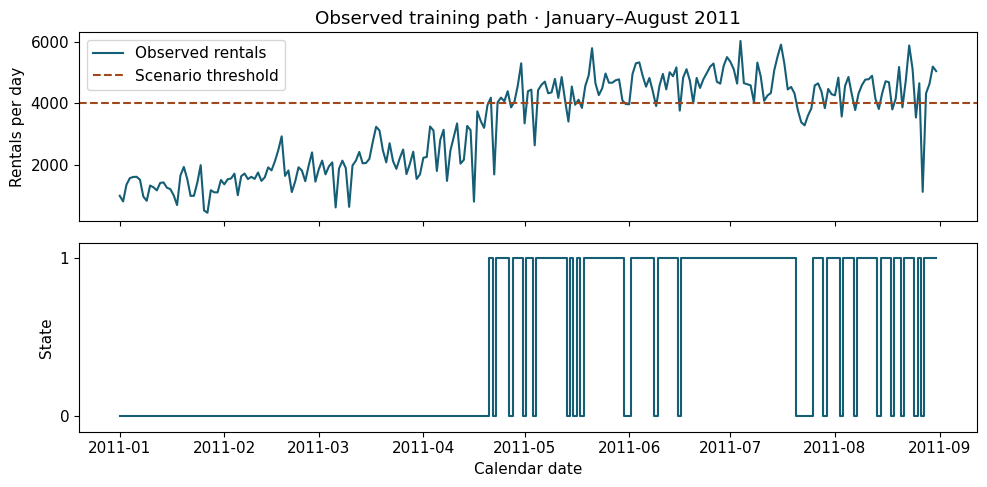

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(train["dteday"], train["cnt"], color="#155e75", label="Observed rentals")
axes[0].axhline(THRESHOLD, color="#a0471c", ls="--", label="Scenario threshold")
axes[0].set(ylabel="Rentals per day", title="Observed training path · January–August 2011")
axes[0].legend(loc="upper left")
axes[1].step(train["dteday"], y_train, where="mid", color="#155e75")
axes[1].set(xlabel="Calendar date", ylabel="State", yticks=[0, 1], ylim=(-0.1, 1.1))
fig.tight_layout()
plt.show()

## 2. Specify a first-order, time-homogeneous Markov model
The **Markov assumption** says that the present state summarizes the past information used by this model:

$$P(Y_{t+1}=j\mid Y_t=i,Y_{t-1},\ldots,Y_1)=P(Y_{t+1}=j\mid Y_t=i).$$

**Time homogeneity** adds that these conditional probabilities do not depend on calendar day. With row and column order **$[0,1]$**, define

$$P_{ij}=P(Y_{t+1}=j\mid Y_t=i),\qquad
P=\begin{pmatrix}1-a&a\\b&1-b\end{pmatrix},\quad a,b\in[0,1].$$

Rows represent **today/origin**; columns represent **tomorrow/destination**. Each row is a probability distribution: $P_{ij}\ge0$ and $\sum_jP_{ij}=1$. Here $a$ is the probability of entering state $1$ from $0$, and $b$ is the probability of leaving state $1$.

An initial row distribution $\nu_0=[P(Y_0=0),P(Y_0=1)]$ plus $P$ specifies the model. For a forecast conditional on an observed state $i$, use the point mass $\nu_0=e_i$. The index $0$ labels the forecast origin, not an extra day of observed data. These are predictive assumptions, not causal statements.

### Estimate transitions using only within-training pairs
For the $m=243$ training days, count only the $m-1=242$ adjacent pairs entirely inside January–August:

$$N_{ij}=\sum_{t=1}^{m-1}1\{y_t=i,y_{t+1}=j\},\qquad N_i=\sum_jN_{ij}.$$

Conditional on the initial state, the Markov likelihood is proportional to $\prod_{i,j}P_{ij}^{N_{ij}}$. Maximizing each row gives

$$\widehat P_{ij}=N_{ij}/N_i\quad\text{when }N_i>0.$$

The final training day has no within-training outgoing transition. The August 31–September 1 pair is **not** used in fitting. A row with $N_i=0$ is unidentified: division by zero cannot produce a valid fitted row.

An optional symmetric pseudocount $\eta>0$ gives $\widetilde P_{ij}=(N_{ij}+\eta)/(N_i+2\eta)$. This is a modeling/regularization choice, not the unsmoothed MLE. The default is $\eta=0$; we raise an error for an unsupported row instead of silently filling it in.

In [5]:
def transition_counts(states):
    states = np.asarray(states)
    if states.ndim != 1 or not np.isin(states, [0, 1]).all():
        raise ValueError("states must be a one-dimensional binary sequence")
    counts = np.zeros((2, 2), dtype=int)
    np.add.at(counts, (states[:-1].astype(int), states[1:].astype(int)), 1)
    return counts

In [6]:
def fit_transition(counts, eta=0.0):
    counts = np.asarray(counts, dtype=float)
    if counts.shape != (2, 2) or not np.isfinite(counts).all() or (counts < 0).any():
        raise ValueError("counts must be a finite, nonnegative 2 by 2 matrix")
    if not np.isfinite(eta) or eta < 0:
        raise ValueError("eta must be finite and nonnegative")
    support = counts.sum(axis=1)
    if eta == 0 and (support == 0).any():
        raise ValueError("An origin state has no observed outgoing pairs; MLE row undefined.")
    return (counts + eta) / (support[:, None] + 2 * eta)

In [7]:
N = transition_counts(y_train)
P_hat = fit_transition(N)  # eta=0: no smoothing
p_iid = float(y_train.mean())  # 109 / 243, inherited Module 1 baseline
P_iid = np.array([[1 - p_iid, p_iid], [1 - p_iid, p_iid]])
assert N.sum() == len(train) - 1 == 242
assert np.array_equal(N, [[114, 20], [19, 89]])
assert (P_hat >= 0).all() and np.allclose(P_hat.sum(axis=1), 1)

For example, $\widehat P_{01}$ is the number of observed $0\to1$ transitions divided by **all transitions out of state $0$**, not all 242 pairs. Origin support matters: a row estimated from few pairs is less informed by data. These denominators count transitions, so they need not equal the number of days in each state.

The iid baseline has two identical rows $[1-\widehat p,\widehat p]$, where $\widehat p=109/243$. Unlike the fitted Markov model, its next-day probability ignores the origin state.

In [8]:
labels = pd.Index([0, 1], name="origin state")
display(pd.DataFrame(N, index=labels, columns=pd.Index([0, 1], name="destination")))
display(pd.DataFrame(P_hat, index=labels, columns=pd.Index([0, 1], name="destination")))
display(pd.DataFrame({"outgoing training pairs": N.sum(axis=1),
                      "Markov P(next=1)": P_hat[:, 1],
                      "iid P(next=1)": p_iid}, index=labels))
print("Last training date/state:", train["dteday"].iloc[-1].date(), y_train[-1])

destination,0,1
origin state,,
0,114,20
1,19,89


destination,0,1
origin state,,
0,0.850746,0.149254
1,0.175926,0.824074


,outgoing training pairs,Markov P(next=1),iid P(next=1)
origin state,,,
0,134,0.149254,0.44856
1,108,0.824074,0.44856


Last training date/state: 2011-08-31 1


## 3. Predict multiple steps by summing over intermediate states
For two steps, the intermediate state is unknown. Sum over its possible values:

$$P(Y_{t+2}=j\mid Y_t=i)=\sum_{k\in\{0,1\}}P_{ik}P_{kj}=(P^2)_{ij}.$$

This is matrix multiplication, **not elementwise squaring**. For the illustrative scenario

$$P_{\mathrm{demo}}=\begin{pmatrix}0.8&0.2\\0.3&0.7\end{pmatrix},\quad
(P_{\mathrm{demo}}^2)_{01}=0.8(0.2)+0.2(0.7)=0.30,$$
$$ (P_{\mathrm{demo}}^2)_{11}=0.3(0.2)+0.7(0.7)=0.55.$$

More generally, with row-vector convention,

$$\nu_h=\nu_0P^h,\qquad q_h(i)=P(Y_{t+h}=1\mid Y_t=i)=(P^h)_{i1},\qquad P^0=I.$$

The Chapman–Kolmogorov composition rule is $P^{r+s}=P^rP^s$: sum over the possible state after the first $r$ steps, then predict $s$ more. The endpoint event $Y_{t+h}=1$ differs from visiting state $1$ **at least once** during the next $h$ steps; paths can enter state $1$ and leave before the endpoint. We predict the endpoint here.

Use `np.linalg.matrix_power(P, h)`; Python's `P ** h` raises each entry separately. A transpose changes which direction the probabilities describe.

In [9]:
P_demo = np.array([[0.8, 0.2], [0.3, 0.7]])  # scenario, not estimated data
P_demo_2_hand = np.array([[0.8*0.8 + 0.2*0.3, 0.8*0.2 + 0.2*0.7],
                         [0.3*0.8 + 0.7*0.3, 0.3*0.2 + 0.7*0.7]])
assert np.allclose(np.linalg.matrix_power(P_demo, 0), np.eye(2))
assert np.allclose(np.linalg.matrix_power(P_demo, 1), P_demo)
assert np.allclose(np.linalg.matrix_power(P_demo, 2), P_demo_2_hand)
assert np.allclose(np.linalg.matrix_power(P_demo, 7),
                   np.linalg.matrix_power(P_demo, 3) @ np.linalg.matrix_power(P_demo, 4))
assert np.allclose(P_demo_2_hand, [[0.70, 0.30], [0.45, 0.55]])
assert not np.allclose(P_demo ** 2, P_demo_2_hand)
assert np.allclose(np.array([0.0, 1.0]) @ P_demo_2_hand, [0.45, 0.55])
display(pd.DataFrame(P_hat @ P_hat, index=labels, columns=[0, 1]))
print("Identity, one-step, hand two-step, and row-vector checks passed.")

,0,1
origin state,,
0,0.750027,0.249973
1,0.294644,0.705356


Identity, one-step, hand two-step, and row-vector checks passed.


**Predict:** Will the next-day forecast depend more strongly on today's state than the 30-day forecast? Is its direction guaranteed to be the same for every possible transition matrix?

The following curves are exact probabilities **conditional on the fitted matrix**, for horizons $0$ through $30$. At horizon $0$, $q_0(0)=0$ and $q_0(1)=1$ because the origin is observed. An iid forecast for any positive horizon is $\widehat p$; it does not replace the known origin at $h=0$. We will interpret finite-horizon predictions here; stationary distributions are reserved for Module 3.

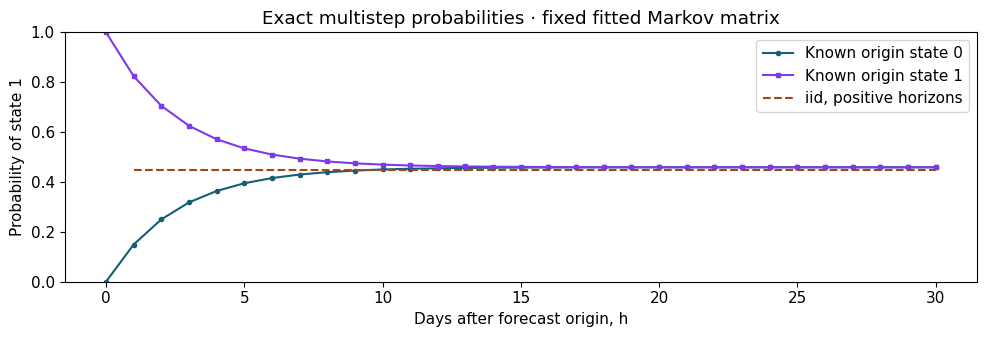

,origin 0,origin 1
1,0.149254,0.824074
7,0.429739,0.493465
30,0.458985,0.458993


In [10]:
horizons = np.arange(31)
q_fitted = np.array([np.linalg.matrix_power(P_hat, int(h))[:, 1] for h in horizons])
fig, ax = plt.subplots()
ax.plot(horizons, q_fitted[:, 0], "o-", ms=3, color="#155e75", label="Known origin state 0")
ax.plot(horizons, q_fitted[:, 1], "s-", ms=3, color="#7c3aed", label="Known origin state 1")
ax.plot(horizons[1:], np.repeat(p_iid, 30), "--", color="#a0471c", label="iid, positive horizons")
ax.set(xlabel="Days after forecast origin, h", ylabel="Probability of state 1", ylim=(0, 1),
       title="Exact multistep probabilities · fixed fitted Markov matrix")
ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame(q_fitted[[1, 7, 30]], index=[1, 7, 30], columns=["origin 0", "origin 1"]))

## 4. Simulate the specified model and verify it
From current state $i$, draw $U\sim\operatorname{Uniform}(0,1)$ and set the next state to $1\{U<P_{i1}\}$. Use fresh random draws at every step and for every independent simulation path.

Our array has $R$ rows (independent paths) and $h+1$ columns. **Column $0$ contains the fixed initial state**, and column $h$ contains the state after exactly $h$ transitions. Thus `paths[:, h]` estimates $q_h$; if counting future exceedance days, sum `paths[:, 1:]` so the observed origin is excluded.

Open the [interactive experiment](../modules/module02.html), predict a change, then run it. Its initial scenario is $P_{\mathrm{demo}}$, origin state $1$, $h=7$, $R=1000$, and seed $6231$, matching the scenario below. The HTML and Python generators use different algorithms; identical numeric seeds do not imply identical paths across platforms.

In [11]:
def validate_simulation(P, initial, horizon, reps):
    P = np.asarray(P, dtype=float)
    if P.shape != (2, 2) or not np.isfinite(P).all() or (P < 0).any():
        raise ValueError("P must be a finite nonnegative 2 by 2 matrix")
    if not np.allclose(P.sum(axis=1), 1):
        raise ValueError("Each origin row must sum to one")
    if initial not in (0, 1):
        raise ValueError("initial must be state 0 or 1")
    if not isinstance(horizon, (int, np.integer)) or horizon < 0:
        raise ValueError("horizon must be a nonnegative integer")
    if not isinstance(reps, (int, np.integer)) or reps < 1:
        raise ValueError("reps must be a positive integer")
    return P

In [12]:
def simulate_chain(P, initial, horizon, reps, seed=SEED):
    """Independent paths; column 0 is the known origin."""
    P = validate_simulation(P, initial, horizon, reps)
    paths = np.empty((reps, horizon + 1), dtype=int)
    paths[:, 0] = initial
    rng = np.random.default_rng(seed)
    for step in range(1, horizon + 1):
        paths[:, step] = (rng.random(reps) < P[paths[:, step - 1], 1]).astype(int)
    return paths

In [13]:
HORIZON, REPS, INITIAL = 7, 1000, 1
paths_demo = simulate_chain(P_demo, INITIAL, HORIZON, REPS)
print("Shape (independent paths, origin + future days):", paths_demo.shape)

Shape (independent paths, origin + future days): (1000, 8)


### Deterministic checks before judging a random discrepancy
For the identity matrix, every path must retain its origin forever. For the alternating matrix $\begin{pmatrix}0&1\\1&0\end{pmatrix}$, every step must switch states. Horizon $0$ must return only the origin. These cases also expose one-step indexing mistakes. Reusing a seed should reproduce the full array in the same Python environment.

In [14]:
identity, alternating = np.eye(2), np.array([[0.0, 1.0], [1.0, 0.0]])
assert np.array_equal(paths_demo, simulate_chain(P_demo, INITIAL, HORIZON, REPS))
assert np.all(simulate_chain(identity, 1, 5, 4) == 1)
assert np.all(simulate_chain(identity, 0, 5, 4) == 0)
assert np.array_equal(simulate_chain(alternating, 0, 5, 4),
                      np.tile([0, 1, 0, 1, 0, 1], (4, 1)))
assert simulate_chain(P_demo, 1, 0, 4).shape == (4, 1)
assert np.all(simulate_chain(P_demo, 1, 0, 4) == 1)
try:
    fit_transition(transition_counts(np.zeros(8, dtype=int)))
except ValueError as error:
    print("Expected unsupported-row check:", error)
else:
    raise AssertionError("An unsupported MLE row must be reported, not silently filled.")
print("Seed replay, deterministic matrices, initial indexing, and zero-row checks passed.")

Expected unsupported-row check: An origin state has no observed outgoing pairs; MLE row undefined.
Seed replay, deterministic matrices, initial indexing, and zero-row checks passed.


### Monte Carlo error at the endpoint
For $R$ **independent paths** with fixed origin and matrix, their endpoints are iid Bernoulli with success probability $q_h$. Therefore

$$\widehat q_h^{\rm MC}=\frac1R\sum_{r=1}^R Y_h^{(r)},\qquad
\operatorname{MCSE}(\widehat q_h^{\rm MC})=\sqrt{\frac{q_h(1-q_h)}R}.$$

This is a numerical error measure for the estimated model probability. States **within** each path are generally dependent; do not treat all $R(h+1)$ array entries as independent trials. Increasing $R$ improves Monte Carlo precision without removing process variability, parameter uncertainty, or model error.

We first check the browser scenario, then apply exactly the same simulator to the fitted bike matrix. These comparisons are conditional on their respective matrices; neither is an interval for true future bike demand.

In [15]:
paths_fitted = simulate_chain(P_hat, INITIAL, 30, REPS, seed=SEED + 1)
mc_rows = []
for name, matrix, paths, checks in [
    ("illustrative scenario", P_demo, paths_demo, [1, 2, 7]),
    ("fitted bike matrix", P_hat, paths_fitted, [1, 7, 30]),
]:
    for h in checks:
        exact = np.linalg.matrix_power(matrix, h)[INITIAL, 1]
        estimate = paths[:, h].mean()
        mcse = np.sqrt(exact * (1 - exact) / REPS)
        mc_rows.append({"model": name, "h": h, "exact": exact, "simulated": estimate,
                        "MCSE": mcse, "difference / MCSE": (estimate - exact) / mcse})
mc_results = pd.DataFrame(mc_rows)
display(mc_results.round(5))
assert (mc_results["difference / MCSE"].abs() < 5).all()  # a generous stochastic smoke check

,model,h,exact,simulated,MCSE,difference / MCSE
0,illustrative scenario,1,0.70000,0.669,0.01449,-2.13920
1,illustrative scenario,2,0.55000,0.519,0.01573,-1.97049
2,illustrative scenario,7,0.40469,0.421,0.01552,1.05096
3,fitted bike matrix,1,0.82407,0.813,0.01204,-0.91973
4,fitted bike matrix,7,0.49347,0.480,0.01581,-0.85168
5,fitted bike matrix,30,0.45899,0.462,0.01576,0.19085


A small simulation discrepancy is expected. The plotted $\pm2$ MCSE bars are approximate **pointwise Monte Carlo error scales**, not simultaneous bands and not prediction intervals for one future state. The exact curve and simulations below use the illustrative scenario. The table above separately checks the fitted matrix.

In [16]:
steps = np.arange(HORIZON + 1)
q_demo = np.array([np.linalg.matrix_power(P_demo, int(h))[INITIAL, 1] for h in steps])
mcse_demo = np.sqrt(q_demo * (1 - q_demo) / REPS)

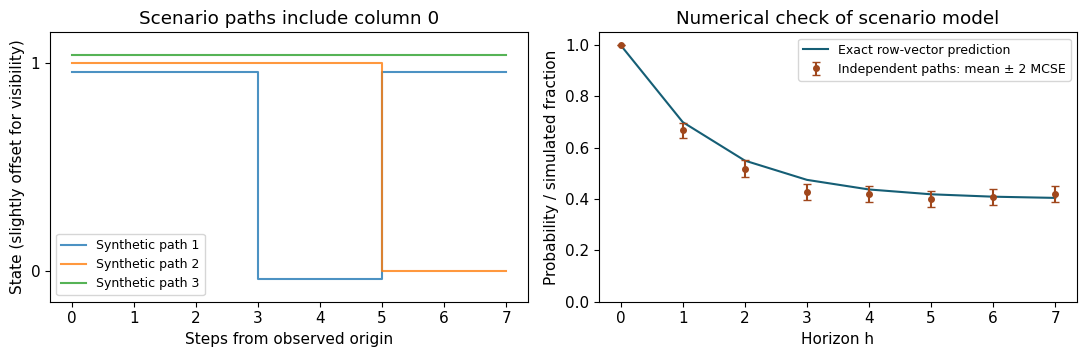

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for r in range(3):
    axes[0].step(steps, paths_demo[r] + 0.04 * (r - 1), where="post", alpha=0.8,
                 label=f"Synthetic path {r + 1}")
axes[0].set(xlabel="Steps from observed origin", ylabel="State (slightly offset for visibility)",
            yticks=[0, 1], ylim=(-0.15, 1.15), title="Scenario paths include column 0")
axes[0].legend(fontsize=9)
axes[1].plot(steps, q_demo, color="#155e75", label="Exact row-vector prediction")
axes[1].errorbar(steps, paths_demo.mean(axis=0), yerr=2 * mcse_demo, fmt="o", ms=4,
                 color="#a0471c", capsize=3, label="Independent paths: mean ± 2 MCSE")
axes[1].set(xlabel="Horizon h", ylabel="Probability / simulated fraction", ylim=(0, 1.05),
            title="Numerical check of scenario model")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

## 5. Make chronological forecasts with the fitted matrix frozen
Return to observed bike states. Fit $\widehat P$ **once** using January–August. For an observed origin date $t$, issue the forecast

$$q_{t,h}=(\widehat P^h)_{y_t,1}.$$

For $h=1$, the first origin is August 31 and the first target is September 1; there are 122 targets. For $h=7$ and $30$, the first origins are also August 31, making first targets September 7 and September 30. We keep only targets inside 2011: there are 116 and 93 forecasts, respectively.

At each new origin it is valid to condition on that day's observed state, including a test-period state now known at forecast time. **Within one $h$-step forecast, the actual intermediate states are unavailable and are not used.** This is a rolling-origin evaluation with fixed parameters, not repeated one-step updating of the same forecast.

Compare on exactly the same target dates at each horizon: the fixed iid forecast $q^{\rm iid}_{t,h}=\widehat p$ and the persistence forecast $q^{\rm persist}_{t,h}=y_t$. The latter assigns probability one to retaining today's state all the way to the target. No future outcomes enter any fitted parameter.

In [18]:
def rolling_forecasts(states, dates, P, p_baseline, first_origin, horizons=(1, 7, 30)):
    frames = []
    for h in horizons:
        origins = np.arange(first_origin, len(states) - h)
        targets = origins + h
        q = np.linalg.matrix_power(P, h)[states[origins], 1]
        frames.append(pd.DataFrame({"h": h, "origin_index": origins, "target_index": targets,
            "origin_date": dates.iloc[origins].to_numpy(),
            "target_date": dates.iloc[targets].to_numpy(),
            "origin_state": states[origins], "observed": states[targets],
            "Markov": q, "iid": p_baseline, "persistence": states[origins].astype(float)}))
    return pd.concat(frames, ignore_index=True)

In [19]:
forecasts = rolling_forecasts(y_all, bike["dteday"], P_hat, p_iid, len(train) - 1)
assert forecasts.groupby("h").size().to_dict() == {1: 122, 7: 116, 30: 93}
assert (forecasts["target_date"] >= SPLIT_DATE).all()
assert ((forecasts["target_date"] - forecasts["origin_date"]).dt.days == forecasts["h"]).all()
assert (forecasts["origin_date"] < forecasts["target_date"]).all()
assert np.allclose(P_hat, fit_transition(transition_counts(y_train)))
display(forecasts.groupby("h").agg(forecasts=("observed", "size"),
    first_origin=("origin_date", "min"), first_target=("target_date", "min"),
    last_target=("target_date", "max")))

,forecasts,first_origin,first_target,last_target
h,,,,
1,122,2011-08-31,2011-09-01,2011-12-31
7,116,2011-08-31,2011-09-07,2011-12-31
30,93,2011-08-31,2011-09-30,2011-12-31


The one-step forecast can take only two values, $\widehat P_{01}$ and $\widehat P_{11}$, selected using yesterday's state. The plot shows that the model learns some persistence while still making errors on switches. Observed target outcomes are revealed only for assessment.

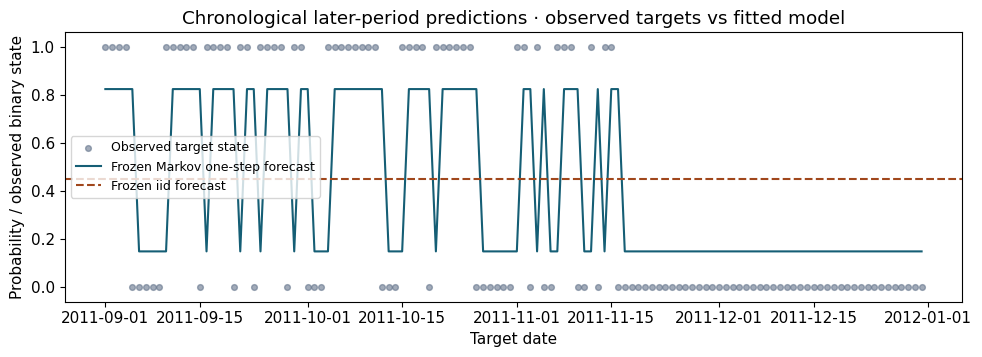

In [20]:
one_step = forecasts.loc[forecasts["h"] == 1].copy()
fig, ax = plt.subplots(figsize=(10, 3.7))
ax.scatter(one_step["target_date"], one_step["observed"], s=17, color="#64748b",
           alpha=0.6, label="Observed target state")
ax.plot(one_step["target_date"], one_step["Markov"], color="#155e75", lw=1.5,
        label="Frozen Markov one-step forecast")
ax.axhline(p_iid, color="#a0471c", ls="--", label="Frozen iid forecast")
ax.set(xlabel="Target date", ylabel="Probability / observed binary state", ylim=(-0.06, 1.06),
       title="Chronological later-period predictions · observed targets vs fitted model")
ax.legend(loc="center left", fontsize=9)
fig.tight_layout()
plt.show()

### Score forecasts and inspect calibration
For $n_h$ forecasts at a fixed horizon, use the Brier score

$$\operatorname{BS}_h=\frac1{n_h}\sum_t (y_{t+h}-q_{t,h})^2.$$

Lower is better. Compare models **within the same horizon and target set**; different horizons here use different target dates. Forecast errors can be temporally dependent, particularly for overlapping horizons, so these averages do not justify iid standard-error formulas or a significance claim.

One-step calibration groups forecasts by the known origin state. In each group compare predicted probability with the observed fraction of target states equal to $1$. These are only two forecast levels; two points cannot establish calibration generally. Group sizes and chronological changes matter.

In [21]:
model_names = ["Markov", "iid", "persistence"]
score_rows = []
for h, group in forecasts.groupby("h"):
    row = {"h": h, "forecasts": len(group)}
    row.update({name: np.mean((group["observed"] - group[name]) ** 2) for name in model_names})
    score_rows.append(row)
scores = pd.DataFrame(score_rows).set_index("h")
calibration = one_step.groupby("origin_state").agg(
    forecasts=("observed", "size"), predicted=("Markov", "mean"), observed=("observed", "mean"))
display(scores.round(6))
display(calibration.round(6))
assert np.allclose(scores.loc[1, model_names], [0.174887057949, 0.241683414358, 0.221311475410])

,forecasts,Markov,iid,persistence
h,,,,
1,122,0.174887,0.241683,0.221311
7,116,0.233163,0.240229,0.336207
30,93,0.235365,0.232181,0.462366


,forecasts,predicted,observed
origin_state,,,
0,73,0.149254,0.178082
1,49,0.824074,0.714286


The fitted Markov model scores better than both baselines for one day and seven days in this development comparison. At 30 days, the iid baseline scores slightly better. Knowing the current state helps less over long horizons for this fitted matrix; a next-day improvement is not a promise of useful month-ahead prediction.

The one-step forecast after state $1$ is about $0.824$, while the later observed fraction is about $0.714$. This is a useful warning about overprediction in that group. It is a descriptive mismatch, not by itself a calibrated hypothesis test or proof of a single cause.

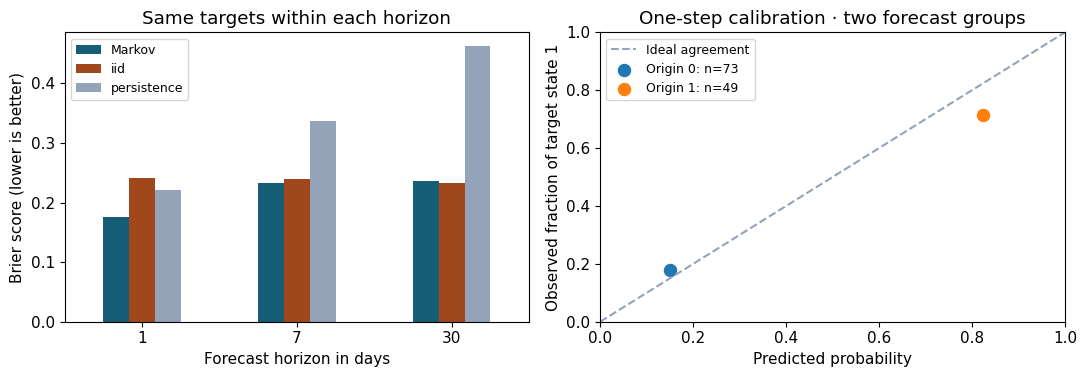

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
scores[model_names].plot.bar(ax=axes[0], color=["#155e75", "#a0471c", "#94a3b8"], rot=0)
axes[0].set(xlabel="Forecast horizon in days", ylabel="Brier score (lower is better)",
            title="Same targets within each horizon")
axes[0].legend(fontsize=9)
axes[1].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Ideal agreement")
for origin, row in calibration.iterrows():
    axes[1].scatter(row["predicted"], row["observed"], s=75,
                    label=f"Origin {origin}: n={int(row['forecasts'])}")
axes[1].set(xlabel="Predicted probability", ylabel="Observed fraction of target state 1",
            xlim=(0, 1), ylim=(0, 1), title="One-step calibration · two forecast groups")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

### Diagnose changing transitions without refitting the forecasts
The within-test transition table uses **121 pairs**, September 1–2 through December 30–31. It excludes the August 31–September 1 boundary pair. Its empirical fractions are diagnostic summaries of later observations, **not replacement parameters** for forecasts already scored.

This differs from the one-step calibration table, which has 122 forecasts and includes the boundary pair. That is why its state-$1$ support and observed rate differ slightly. Every denominator should answer a clearly stated question.

In [23]:
N_test_diagnostic = transition_counts(test["y"].to_numpy())
P_test_diagnostic = fit_transition(N_test_diagnostic)
assert N_test_diagnostic.sum() == 121
assert np.array_equal(N_test_diagnostic, [[60, 13], [14, 34]])
display(pd.DataFrame(N_test_diagnostic, index=labels, columns=[0, 1]))
display(pd.DataFrame({"within-training P(next=1)": P_hat[:, 1],
                      "within-test P(next=1), diagnostic": P_test_diagnostic[:, 1],
                      "within-test origin support": N_test_diagnostic.sum(axis=1)}, index=labels))
print("Forecast parameters remain the training-only matrix:")
print(P_hat)

,0,1
origin state,,
0,60,13
1,14,34


,within-training P(next=1),"within-test P(next=1), diagnostic",within-test origin support
origin state,,,
0,0.149254,0.178082,73
1,0.824074,0.708333,48


Forecast parameters remain the training-only matrix:
[[0.85074627 0.14925373]
 [0.17592593 0.82407407]]


## 6. Interpret what the model does and does not explain
The Markov model uses today's binary state to improve some forecasts in this one-year development comparison. It still assumes that all history beyond that state is irrelevant and that the same transition probabilities apply in every season. Neither assumption follows from row normalization or successful simulation.

- **State design:** Thresholding loses count magnitude and history. More informative states or measured predictors may help, but more states also create sparse or unobserved transition rows.
- **Calendar change:** Season, weather, working days, and changing system use can affect transitions. One year cannot establish repeatable annual behavior or a causal mechanism.
- **Uncertainty:** Simulations condition on $\widehat P$. Parameter uncertainty, model choice, and changing conditions remain even as $R\to\infty$.
- **Evaluation:** We reused the Module 1 holdout for development. Choose changes transparently, then assess a final selected model on new chronological data. Avoid shuffling temporal observations.

For your sustained project, choose a measurable state and time step, explain what information it discards, and compare a simple baseline against a frozen forecast model on matching future targets. Record a decision-relevant threshold and one sensitivity scenario; this is preparation for the existing project, not a second project.

## 7. Student exercises · complete in your own words
Submit these with your Module 1 work as Concept Lab 1. Allow about 25–35 minutes. Keep each interpretation to 2–4 sentences plus the requested calculation or small table. The worked computations above are examples; the exercises below are intentionally unanswered.

**Exercise 1 — States, orientation, and two steps.** Define the time index and state space of $Y_t$, explain what information the threshold discards, and distinguish a known origin state from an initial distribution. Using the new exercise matrix $Q=\begin{pmatrix}0.7&0.3\\0.4&0.6\end{pmatrix}$, compute $Q^2$ by hand and interpret its two entries in column $1$. State the row/column order and write the two-step row distribution for an origin in state $0$. Why is `Q ** 2` not the requested computation? Explain why “state $1$ at the two-day endpoint” differs from “state $1$ at least once in the next two days.”

**Your response:** _Write here._

**Exercise 2 — Endpoint simulation and Monte Carlo precision.** Use the illustrative $P_{\mathrm{demo}}$, initial state $1$, and horizon $7$. Before running, predict the MCSE change from $R=250$ to $R=4000$. At both replication counts, use seeds 6231 and 6232; tabulate the simulated endpoint frequency, exact matrix-power probability, MCSE, and signed error. Identify the array column representing the endpoint. Explain why a larger run need not have smaller realized absolute error and why these intervals omit parameter and model uncertainty.

In [24]:
# Your computation for Exercise 2.
# Reuse simulate_chain; keep the worked-example variables intact.

**Your interpretation:** _Write here._

**Exercise 3 — Audit the seven-day evaluation.** Reconstruct the first and last valid origin/target dates for $h=7$, verify the forecast count, and recompute all three Brier scores on those same targets. Inspect one forecast whose origin occurs in September: list exactly which observed states are available at that origin and identify which intermediate realized states must not enter its seven-day prediction. Explain why updating the known origin at a later forecast date is valid while refitting $P$ on all of 2011 is not. State the limitation of reusing this development holdout and one extra data field you would investigate before final validation.

In [25]:
# Your computation for Exercise 3.
# Keep P_hat and p_iid fixed; preserve chronological origin and target dates.

**Your interpretation:** _Write here._

**Exercise 4 — Audit generated code, no AI account required.** An assistant proposes the following for a seven-day forecast after state $1$, claiming both correct probability calculation and honest held-out validation:

```python
P_candidate = fit_transition(transition_counts(y_all))
nu0 = np.array([0.0, 1.0])
nu7 = nu0 @ (P_candidate ** 7).T
```

Identify and repair the training-data leakage, elementwise power, and row/column orientation errors. Check row sums and nonnegativity, the $h=0$ and $h=1$ distributions, and a hand-computed $h=2$ case using the asymmetric illustrative matrix. Explain why a normalized matrix alone cannot detect leakage, and why testing only an identity or symmetric matrix could miss an orientation bug. AI assistance is optional; all claims must be checked by you.

In [26]:
# Your audit and repair for Exercise 4.
# Demonstrate checks that distinguish the specific incorrect claims from the repaired code.

**Your explanation and verification evidence:** _Write here._

### Optional extension · smoothing and state sensitivity
Compare thresholds $c=3000$ and $5000$ with the same January–August fit and chronological later evaluation. For each, report transition counts, row supports, and the one-step Brier comparison with its own iid baseline. The thresholds define different outcomes, so scores across thresholds are not a fair contest for a universally “best” model.

Then compare $\eta=0$ and $\eta=0.5$ on the **same** threshold. If no training pairs leave a state, explain why the unsmoothed MLE row is undefined. With symmetric pseudocounts, an unsupported row becomes $[0.5,0.5]$ because of the assumption, not evidence. Try the artificial scenario $c=10000$ to expose this case. Do not silently replace an undefined row with zeros. More informative states and smoothing need independent validation; inspecting this holdout to choose them uses it for development.

### Responsible AI and reproducibility record
Complete this even if no AI tool was used:

- **Consequential assistance:** _None, or tool/version/date and what it helped produce._
- **Verification performed:** _A mathematical check and a chronological data check you performed yourself._
- **My explanation:** _One Markov assumption you can defend and one you would investigate._
- **Changes from the starter:** _States, thresholds, smoothing, seeds, parameters, or code changed._

Be ready to explain, modify, and defend submitted work. Do not upload private project data without authorization. Simulation agreement verifies a model implementation; predictive evaluation assesses its usefulness on observations.

## Reproducibility information
The code above checks the bundled data hash, dates, training pair count, orientation, powers, probability rows, deterministic simulators, seed replay, horizon alignment, and later forecast counts. Five embedded figures distinguish observed records, synthetic paths, and exact model predictions.

The cell below records the environment. Module 3 develops stationary distributions, absorption, and hitting times; they are not needed to justify this module's finite-horizon predictions.

In [27]:
versions = {name: metadata.version(name) for name in
            ["numpy", "pandas", "scipy", "matplotlib", "nbformat", "nbclient", "ipykernel"]}
print("Python", platform.python_version())
print(json.dumps(versions, indent=2))
print("Scenario seed:", SEED, "| Fitted-model simulation seed:", SEED + 1)
print("CSV SHA-256:", source["sample_sha256"])

Python 3.10.9
{
  "numpy": "1.24.2",
  "pandas": "2.0.0",
  "scipy": "1.10.1",
  "matplotlib": "3.7.1",
  "nbformat": "5.7.0",
  "nbclient": "0.5.13",
  "ipykernel": "6.19.2"
}
Scenario seed: 6231 | Fitted-model simulation seed: 6232
CSV SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329
